# Experiment 8 — Hindi Abstractive Summarization: mT5 vs mBART

## Aim
To implement and evaluate abstractive text summarization using **mT5** and **mBART** on the Hindi subset of **XL-Sum**, and compare both models using:

- ROUGE-1
- ROUGE-2
- ROUGE-L
- multilingual BERTScore Precision
- multilingual BERTScore Recall
- multilingual BERTScore F1

## Corrections made after the previous Colab run
The previous run successfully generated meaningful Hindi summaries, but the generic ROUGE implementation produced misleading near-zero scores because its default tokenization is designed primarily around Latin/English-style tokens.

This notebook therefore:
1. Loads Hindi XL-Sum directly from Parquet (no legacy builder-script prompt).
2. Uses XL-Sum-fine-tuned mT5 and mBART checkpoints.
3. Evaluates both models on exactly the same samples.
4. Uses **Unicode/Hindi-aware whitespace tokenization for ROUGE**.
5. Uses multilingual BERTScore for semantic evaluation.
6. Reports mean metrics, per-example metrics, variability, qualitative examples, and model winners.
7. Includes defensive checks for empty summaries and GPU memory cleanup.

> Recommended runtime: **Google Colab T4 GPU**


## 1. Install Required Libraries


In [1]:
!pip -q install "transformers>=4.46,<5" "datasets>=4.0" bert_score sentencepiece accelerate safetensors rouge-score


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Imports, Reproducibility and GPU


In [2]:
import gc
import re
import random
import unicodedata
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from bert_score import score as bert_score
from rouge_score import rouge_scorer

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: Enable a GPU in Colab for practical inference speed.")


PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


## 3. Load Hindi XL-Sum Directly from Parquet


In [3]:
# Pinned XL-Sum repository revision for reproducibility.
XLSUM_REVISION = "014d1559dcde03c72beff7d2e617f9792a54fd39"

TEST_URL = (
    "https://huggingface.co/datasets/csebuetnlp/xlsum/resolve/"
    + XLSUM_REVISION
    + "/hindi/xlsum-test.parquet"
)

test_dataset = load_dataset(
    "parquet",
    data_files={"test": TEST_URL},
    split="test"
)

required_columns = {"text", "summary"}
missing = required_columns - set(test_dataset.column_names)

if missing:
    raise ValueError(f"Required XL-Sum columns missing: {missing}")

print(test_dataset)
print("Rows:", len(test_dataset))
print("Columns:", test_dataset.column_names)


hindi/xlsum-test.parquet:   0%|          | 0.00/21.5M [00:00<?, ?B/s]

Generating test split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['id', 'url', 'title', 'summary', 'text'],
    num_rows: 8847
})
Rows: 8847
Columns: ['id', 'url', 'title', 'summary', 'text']


## 4. Inspect a Sample


In [4]:
sample = test_dataset[0]

print("ARTICLE:\n")
print(sample["text"])

print("\n" + "="*100)
print("\nREFERENCE SUMMARY:\n")
print(sample["summary"])


ARTICLE:

नासिक की एक अदालत ने महाराष्ट्र पुलिस के आतंकवाद निरोधक दस्ते (एटीएस) के अनुरोध पर ये आदेश दिया है. सरकारी वकील अजय मिश्रा ने यह जानकारी दी है. कुछ दिन पहले एटीएस ने मध्य प्रदेश के इंदौर शहर से साध्वी प्रज्ञा सिंह ठाकुर को गिरफ़्तार किया था. नासिक की अदालत ने प्रज्ञा सिंह और दो अन्य अभियुक्तों को तीन नवंबर तक के लिए पुलिस हिरासत में रखने का भी फ़ैसला दिया. आवेदन एटीएस ने अदालत में इस टेस्ट के लिए आवेदन किया था और कहा था कि जाँच के लिए ये टेस्ट ज़रूरी हैं. हालाँकि सरकारी वकील अजय मिश्रा ने यह जानकारी नहीं दी कि साध्वी प्रज्ञा सिंह ठाकुर को कब इस टेस्ट से गुज़रना होगा. पत्रकारों के एक सवाल के जवाब में उन्होंने बताया कि उन्हें इस बात की कोई जानकारी नहीं है कि इसी मामले में दो पूर्व सैनिक अधिकारियों को भी अदालत में पेश किया जाना है. इन दो पूर्व सैनिक अधिकारियों से मालेगाँव और सूरत के मोडासा में हुए धमाकों के सिलसिले में पूछताछ की जा रही है. बीबीसी संवाददाता रेहाना बस्तीवाला ने पुलिस सूत्रों के हवाले से इसकी पुष्टि की है और बताया है कि इनमें एक रिटायर्ड मेजर जनरल भी है. मालेगाँव म

## 5. Exploratory Data Analysis


In [5]:
eda_n = min(2000, len(test_dataset))
eda = pd.DataFrame(test_dataset.select(range(eda_n)))

eda["article_words"] = eda["text"].apply(lambda x: len(str(x).split()))
eda["summary_words"] = eda["summary"].apply(lambda x: len(str(x).split()))

print("Missing values:")
display(eda[["text", "summary"]].isna().sum())

print("\nLength statistics:")
display(eda[["article_words", "summary_words"]].describe().round(2))


Missing values:


,0
text,0
summary,0



Length statistics:


,article_words,summary_words
count,2000.00,2000.00
mean,456.52,26.88
std,263.51,7.40
min,76.00,9.00
25%,253.00,21.00
50%,371.00,26.00
75%,592.25,32.00
max,1264.00,52.00


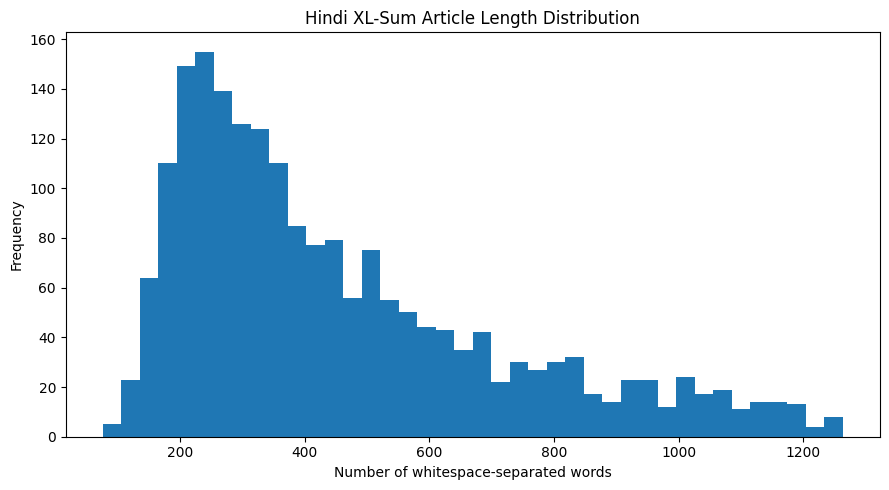

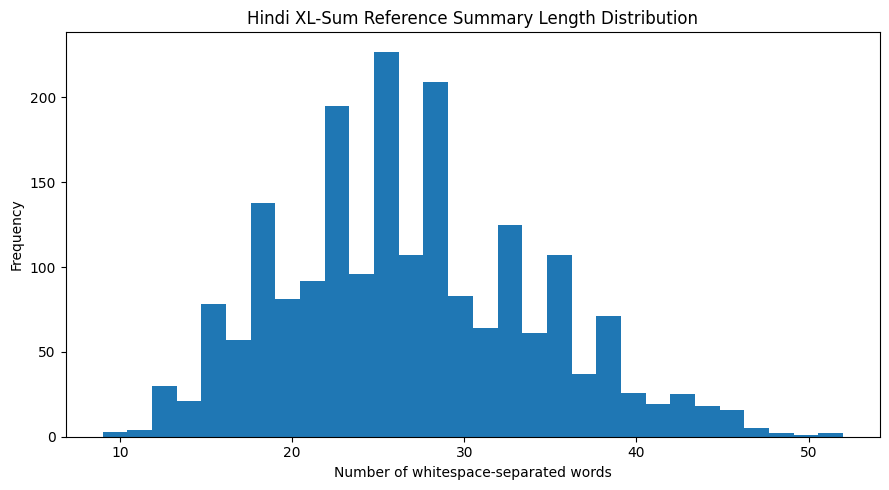

In [6]:
plt.figure(figsize=(9,5))
plt.hist(eda["article_words"], bins=40)
plt.title("Hindi XL-Sum Article Length Distribution")
plt.xlabel("Number of whitespace-separated words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,5))
plt.hist(eda["summary_words"], bins=30)
plt.title("Hindi XL-Sum Reference Summary Length Distribution")
plt.xlabel("Number of whitespace-separated words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## 6. Evaluation Subset

The previous notebook used 20 samples. This version defaults to **50 samples** for more stable metrics while remaining practical on a T4 GPU.

Set `NUM_SAMPLES = 100` if you want a stronger final evaluation and have enough runtime.


In [7]:
NUM_SAMPLES = 50

eval_dataset = (
    test_dataset
    .shuffle(seed=SEED)
    .select(range(min(NUM_SAMPLES, len(test_dataset))))
)

articles = list(eval_dataset["text"])
references = list(eval_dataset["summary"])

assert len(articles) == len(references) > 0
assert all(str(x).strip() for x in articles)
assert all(str(x).strip() for x in references)

print("Evaluation samples:", len(articles))


Evaluation samples: 50


# Part A — mT5


Model: **csebuetnlp/mT5_multilingual_XLSum**

This is an mT5 checkpoint already fine-tuned for multilingual XL-Sum summarization. We evaluate it rather than performing unstable FP16 fine-tuning in Colab.


## 7. Load mT5


In [8]:
MT5_MODEL = "csebuetnlp/mT5_multilingual_XLSum"

mt5_tokenizer = AutoTokenizer.from_pretrained(
    MT5_MODEL,
    use_fast=False
)

mt5_model = AutoModelForSeq2SeqLM.from_pretrained(
    MT5_MODEL,
    dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    low_cpu_mem_usage=True
).to(device)

mt5_model.eval()
print("Loaded:", MT5_MODEL)


tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/730 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


pytorch_model.bin:   0%|          | 0.00/2.33G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.33G [00:00<?, ?B/s]

Loaded: csebuetnlp/mT5_multilingual_XLSum


## 8. mT5 Generation Function


In [9]:
def summarize_mt5(text):
    batch = mt5_tokenizer(
        text,
        return_tensors="pt",
        max_length=512,
        truncation=True
    )
    batch = {k: v.to(device) for k, v in batch.items()}

    with torch.inference_mode():
        output = mt5_model.generate(
            **batch,
            max_new_tokens=80,
            min_new_tokens=8,
            num_beams=4,
            length_penalty=1.0,
            no_repeat_ngram_size=3,
            early_stopping=True
        )

    summary = mt5_tokenizer.decode(
        output[0],
        skip_special_tokens=True
    ).strip()

    return summary


## 9. mT5 Sanity Check


In [10]:
mt5_demo = summarize_mt5(articles[0])

print("REFERENCE:\n", references[0])
print("\nmT5 GENERATED:\n", mt5_demo)

if not mt5_demo:
    raise RuntimeError("mT5 returned an empty summary.")

print("\nmT5 sanity check passed.")


REFERENCE:
 अमरीकी शहर बॉस्टन में पुलिस ने कहा है कि दूसरे ऐसे संदिग्ध व्यक्ति को पकड़ लिया गया है जिस पर शहर में सोमवार को मैराथन के दौरान धमाकों में शामिल होने का शक है. गंभीर रूप से घायल इस व्यक्ति को अस्पताल में भर्ती कराया गया है.

mT5 GENERATED:
 अमरीका के बॉस्टन शहर में सोमवार को हुए बम धमाकों के एक संदिग्ध को पकड़ा गया है.

mT5 sanity check passed.


## 10. Generate mT5 Summaries


In [11]:
mt5_predictions = []

for i, article in enumerate(articles, 1):
    summary = summarize_mt5(article)

    if not summary:
        summary = "[EMPTY]"

    mt5_predictions.append(summary)
    print(f"mT5: {i}/{len(articles)}", end="\r")

print("\nmT5 generation complete.")
print("Empty outputs:", sum(x == "[EMPTY]" for x in mt5_predictions))


mT5: 50/50
mT5 generation complete.
Empty outputs: 0


## 11. Clear mT5 from GPU


In [12]:
del mt5_model
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("mT5 removed from GPU.")


mT5 removed from GPU.


# Part B — mBART


Model: **mskayacioglu/mbart50-xlsum**

This mBART-50 checkpoint is fine-tuned for multilingual XL-Sum summarization and supports Hindi using the `hi_IN` language code.


## 12. Load mBART


In [13]:
MBART_MODEL = "mskayacioglu/mbart50-xlsum"

mbart_tokenizer = AutoTokenizer.from_pretrained(MBART_MODEL)
mbart_tokenizer.src_lang = "hi_IN"
mbart_tokenizer.tgt_lang = "hi_IN"

mbart_model = AutoModelForSeq2SeqLM.from_pretrained(
    MBART_MODEL,
    dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    low_cpu_mem_usage=True
).to(device)

mbart_model.eval()

HI_ID = mbart_tokenizer.lang_code_to_id["hi_IN"]

print("Loaded:", MBART_MODEL)
print("Hindi language token ID:", HI_ID)


tokenizer_config.json: 0.00B [00:00, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/992 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/2.44G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/256 [00:00<?, ?B/s]

Loaded: mskayacioglu/mbart50-xlsum
Hindi language token ID: 250010


## 13. mBART Generation Function


In [14]:
def summarize_mbart(text):
    mbart_tokenizer.src_lang = "hi_IN"

    batch = mbart_tokenizer(
        text,
        return_tensors="pt",
        max_length=512,
        truncation=True
    )
    batch = {k: v.to(device) for k, v in batch.items()}

    with torch.inference_mode():
        output = mbart_model.generate(
            **batch,
            forced_bos_token_id=HI_ID,
            max_new_tokens=80,
            min_new_tokens=8,
            num_beams=4,
            length_penalty=1.0,
            no_repeat_ngram_size=3,
            early_stopping=True
        )

    summary = mbart_tokenizer.decode(
        output[0],
        skip_special_tokens=True
    ).strip()

    return summary


## 14. mBART Sanity Check


In [15]:
mbart_demo = summarize_mbart(articles[0])

print("REFERENCE:\n", references[0])
print("\nmBART GENERATED:\n", mbart_demo)

if not mbart_demo:
    raise RuntimeError("mBART returned an empty summary.")

print("\nmBART sanity check passed.")


REFERENCE:
 अमरीकी शहर बॉस्टन में पुलिस ने कहा है कि दूसरे ऐसे संदिग्ध व्यक्ति को पकड़ लिया गया है जिस पर शहर में सोमवार को मैराथन के दौरान धमाकों में शामिल होने का शक है. गंभीर रूप से घायल इस व्यक्ति को अस्पताल में भर्ती कराया गया है.

mBART GENERATED:
 अमरीका के बॉस्टन शहर में सोमवार को हुए धमाकों के संदिग्ध को पकड़ लिया गया है.

mBART sanity check passed.


## 15. Generate mBART Summaries


In [16]:
mbart_predictions = []

for i, article in enumerate(articles, 1):
    summary = summarize_mbart(article)

    if not summary:
        summary = "[EMPTY]"

    mbart_predictions.append(summary)
    print(f"mBART: {i}/{len(articles)}", end="\r")

print("\nmBART generation complete.")
print("Empty outputs:", sum(x == "[EMPTY]" for x in mbart_predictions))


mBART: 50/50
mBART generation complete.
Empty outputs: 0


## 16. Clear mBART from GPU


In [17]:
del mbart_model
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("mBART removed from GPU.")


mBART removed from GPU.


# Part C — Correct Hindi-Aware ROUGE


## Why the previous ROUGE values were misleading

The previous run used the default `evaluate`/ROUGE tokenizer. For Hindi text, that tokenizer can fail to represent Devanagari words appropriately, producing near-zero ROUGE even when generated and reference summaries visibly share words.

Here we normalize Unicode Hindi text and tokenize using whitespace. ROUGE is then computed over those Hindi tokens.


## 17. Hindi Normalization and Tokenizer


In [18]:
def normalize_hindi(text):
    text = unicodedata.normalize("NFC", str(text))
    text = text.replace("\u200c", " ").replace("\u200d", " ")
    text = re.sub(r"\s+", " ", text).strip()
    return text

class HindiWhitespaceTokenizer:
    def tokenize(self, text):
        text = normalize_hindi(text)
        return text.split()

hindi_tokenizer = HindiWhitespaceTokenizer()

rouge_scorer_hi = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=False,
    tokenizer=hindi_tokenizer
)

# Quick tokenizer demonstration
print(hindi_tokenizer.tokenize("अमरीका के बॉस्टन शहर में धमाके हुए।"))


['अमरीका', 'के', 'बॉस्टन', 'शहर', 'में', 'धमाके', 'हुए।']


## 18. Compute Per-Example Hindi ROUGE


In [19]:
def compute_hindi_rouge(predictions, references):
    rows = []

    for pred, ref in zip(predictions, references):
        scores = rouge_scorer_hi.score(
            normalize_hindi(ref),
            normalize_hindi(pred)
        )

        rows.append({
            "ROUGE-1 Precision": scores["rouge1"].precision,
            "ROUGE-1 Recall": scores["rouge1"].recall,
            "ROUGE-1 F1": scores["rouge1"].fmeasure,
            "ROUGE-2 Precision": scores["rouge2"].precision,
            "ROUGE-2 Recall": scores["rouge2"].recall,
            "ROUGE-2 F1": scores["rouge2"].fmeasure,
            "ROUGE-L Precision": scores["rougeL"].precision,
            "ROUGE-L Recall": scores["rougeL"].recall,
            "ROUGE-L F1": scores["rougeL"].fmeasure
        })

    return pd.DataFrame(rows)

mt5_rouge_examples = compute_hindi_rouge(
    mt5_predictions,
    references
)

mbart_rouge_examples = compute_hindi_rouge(
    mbart_predictions,
    references
)

print("mT5 Hindi ROUGE mean:")
display(mt5_rouge_examples.mean().to_frame("Mean").round(4))

print("mBART Hindi ROUGE mean:")
display(mbart_rouge_examples.mean().to_frame("Mean").round(4))


mT5 Hindi ROUGE mean:


,Mean
ROUGE-1 Precision,0.3767
ROUGE-1 Recall,0.3028
ROUGE-1 F1,0.3293
ROUGE-2 Precision,0.1425
ROUGE-2 Recall,0.1163
ROUGE-2 F1,0.1256
ROUGE-L Precision,0.3195
ROUGE-L Recall,0.2587
ROUGE-L F1,0.2805


mBART Hindi ROUGE mean:


,Mean
ROUGE-1 Precision,0.3650
ROUGE-1 Recall,0.3082
ROUGE-1 F1,0.3260
ROUGE-2 Precision,0.1409
ROUGE-2 Recall,0.1159
ROUGE-2 F1,0.1236
ROUGE-L Precision,0.3062
ROUGE-L Recall,0.2590
ROUGE-L F1,0.2738


# Part D — Multilingual BERTScore


## 19. Compute Semantic Similarity with mBERT


In [20]:
# BERTScore uses contextual multilingual representations.
# Running on CPU after model cleanup is safe; if GPU is available it will use CUDA.

bert_device = "cuda" if torch.cuda.is_available() else "cpu"

P_mt5, R_mt5, F_mt5 = bert_score(
    mt5_predictions,
    references,
    model_type="bert-base-multilingual-cased",
    device=bert_device,
    batch_size=4,
    verbose=True
)

P_mb, R_mb, F_mb = bert_score(
    mbart_predictions,
    references,
    model_type="bert-base-multilingual-cased",
    device=bert_device,
    batch_size=4,
    verbose=True
)

mt5_bert = pd.DataFrame({
    "mBERT Precision": P_mt5.cpu().numpy(),
    "mBERT Recall": R_mt5.cpu().numpy(),
    "mBERT F1": F_mt5.cpu().numpy()
})

mbart_bert = pd.DataFrame({
    "mBERT Precision": P_mb.cpu().numpy(),
    "mBERT Recall": R_mb.cpu().numpy(),
    "mBERT F1": F_mb.cpu().numpy()
})

print("mT5 multilingual BERTScore:")
display(mt5_bert.mean().to_frame("Mean").round(4))

print("mBART multilingual BERTScore:")
display(mbart_bert.mean().to_frame("Mean").round(4))


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

calculating scores...
computing bert embedding.


... (7 outputs left out)

done in 1.25 seconds, 40.02 sentences/sec
mT5 multilingual BERTScore:


,Mean
mBERT Precision,0.7738
mBERT Recall,0.7573
mBERT F1,0.7651


mBART multilingual BERTScore:


,Mean
mBERT Precision,0.7678
mBERT Recall,0.7565
mBERT F1,0.7616


# Part E — Final Results


## 20. Final Comparison Table


In [21]:
results = pd.DataFrame({
    "Model": ["mT5", "mBART"],

    "ROUGE-1": [
        mt5_rouge_examples["ROUGE-1 F1"].mean(),
        mbart_rouge_examples["ROUGE-1 F1"].mean()
    ],

    "ROUGE-2": [
        mt5_rouge_examples["ROUGE-2 F1"].mean(),
        mbart_rouge_examples["ROUGE-2 F1"].mean()
    ],

    "ROUGE-L": [
        mt5_rouge_examples["ROUGE-L F1"].mean(),
        mbart_rouge_examples["ROUGE-L F1"].mean()
    ],

    "mBERT Precision": [
        mt5_bert["mBERT Precision"].mean(),
        mbart_bert["mBERT Precision"].mean()
    ],

    "mBERT Recall": [
        mt5_bert["mBERT Recall"].mean(),
        mbart_bert["mBERT Recall"].mean()
    ],

    "mBERT F1": [
        mt5_bert["mBERT F1"].mean(),
        mbart_bert["mBERT F1"].mean()
    ]
}).round(4)

display(results)


,Model,ROUGE-1,ROUGE-2,ROUGE-L,mBERT Precision,mBERT Recall,mBERT F1
0,mT5,0.3293,0.1256,0.2805,0.7738,0.7573,0.7651
1,mBART,0.3260,0.1236,0.2738,0.7678,0.7565,0.7616


## 21. Metric Variability / Standard Deviation


In [22]:
variability = pd.DataFrame({
    "Metric": ["ROUGE-1", "ROUGE-2", "ROUGE-L", "mBERT F1"],

    "mT5 Mean": [
        mt5_rouge_examples["ROUGE-1 F1"].mean(),
        mt5_rouge_examples["ROUGE-2 F1"].mean(),
        mt5_rouge_examples["ROUGE-L F1"].mean(),
        mt5_bert["mBERT F1"].mean()
    ],

    "mT5 Std": [
        mt5_rouge_examples["ROUGE-1 F1"].std(),
        mt5_rouge_examples["ROUGE-2 F1"].std(),
        mt5_rouge_examples["ROUGE-L F1"].std(),
        mt5_bert["mBERT F1"].std()
    ],

    "mBART Mean": [
        mbart_rouge_examples["ROUGE-1 F1"].mean(),
        mbart_rouge_examples["ROUGE-2 F1"].mean(),
        mbart_rouge_examples["ROUGE-L F1"].mean(),
        mbart_bert["mBERT F1"].mean()
    ],

    "mBART Std": [
        mbart_rouge_examples["ROUGE-1 F1"].std(),
        mbart_rouge_examples["ROUGE-2 F1"].std(),
        mbart_rouge_examples["ROUGE-L F1"].std(),
        mbart_bert["mBERT F1"].std()
    ]
}).round(4)

display(variability)


,Metric,mT5 Mean,mT5 Std,mBART Mean,mBART Std
0,ROUGE-1,0.3293,0.1361,0.3260,0.1435
1,ROUGE-2,0.1256,0.1155,0.1236,0.1128
2,ROUGE-L,0.2805,0.1339,0.2738,0.1312
3,mBERT F1,0.7651,0.0500,0.7616,0.0561


## 22. Automatically Identify the Better Model


In [23]:
metric_columns = [
    "ROUGE-1",
    "ROUGE-2",
    "ROUGE-L",
    "mBERT Precision",
    "mBERT Recall",
    "mBERT F1"
]

winner_rows = []

for metric in metric_columns:
    best_idx = results[metric].idxmax()

    winner_rows.append({
        "Metric": metric,
        "Winner": results.loc[best_idx, "Model"],
        "Best Score": results.loc[best_idx, metric]
    })

winners = pd.DataFrame(winner_rows)
display(winners)

win_counts = winners["Winner"].value_counts()

print("\nMetric wins:")
print(win_counts)

overall_winner = win_counts.idxmax()

print(
    f"\nOverall conclusion based on number of metric wins: "
    f"{overall_winner} performs better on this evaluation subset."
)


,Metric,Winner,Best Score
0,ROUGE-1,mT5,0.3293
1,ROUGE-2,mT5,0.1256
2,ROUGE-L,mT5,0.2805
3,mBERT Precision,mT5,0.7738
4,mBERT Recall,mT5,0.7573
5,mBERT F1,mT5,0.7651



Metric wins:
Winner
mT5    6
Name: count, dtype: int64

Overall conclusion based on number of metric wins: mT5 performs better on this evaluation subset.


## 23. ROUGE Comparison Plot


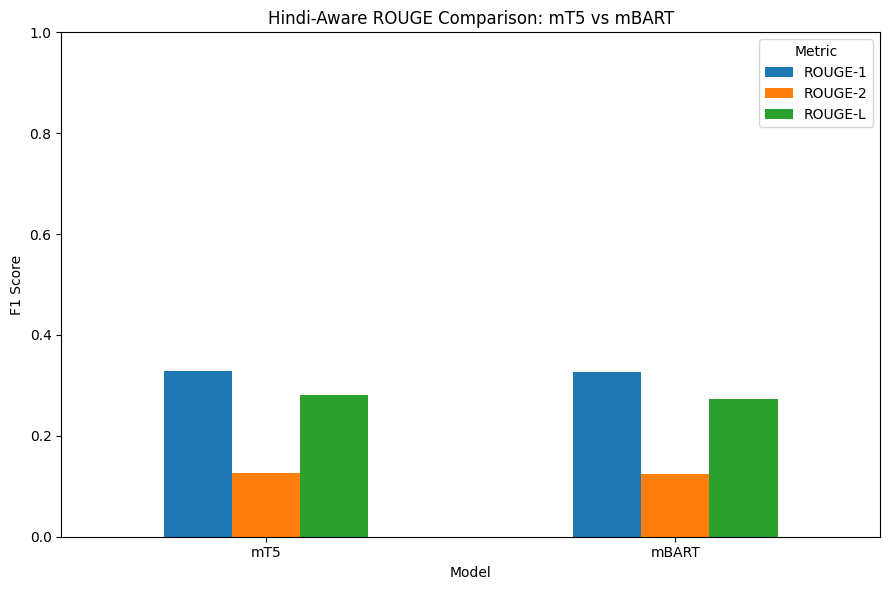

In [24]:
results.set_index("Model")[
    ["ROUGE-1", "ROUGE-2", "ROUGE-L"]
].plot(
    kind="bar",
    figsize=(9,6)
)

plt.title("Hindi-Aware ROUGE Comparison: mT5 vs mBART")
plt.xlabel("Model")
plt.ylabel("F1 Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()


## 24. Multilingual BERTScore Comparison Plot


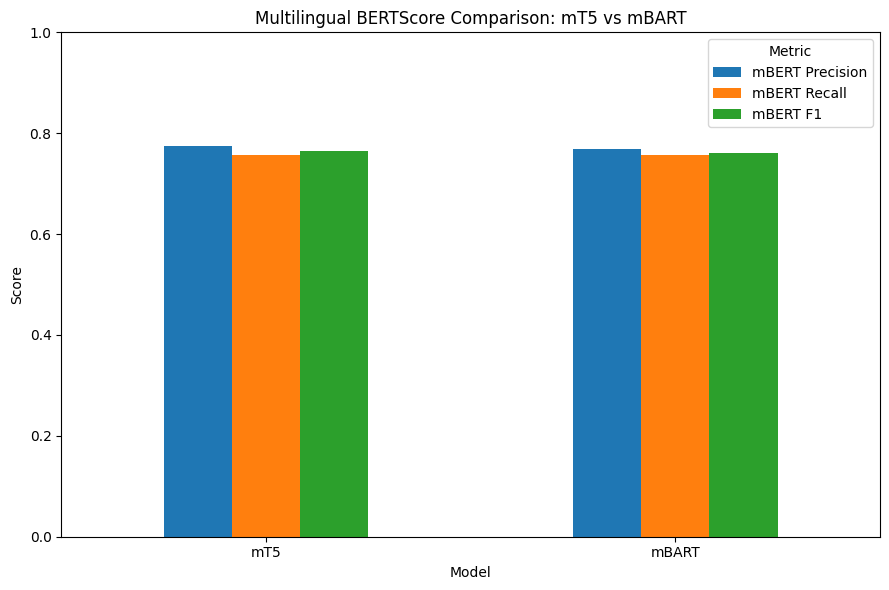

In [25]:
results.set_index("Model")[
    ["mBERT Precision", "mBERT Recall", "mBERT F1"]
].plot(
    kind="bar",
    figsize=(9,6)
)

plt.title("Multilingual BERTScore Comparison: mT5 vs mBART")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()


## 25. Build Detailed Per-Example Results


In [26]:
detailed = pd.DataFrame({
    "Article": articles,
    "Reference": references,
    "mT5 Summary": mt5_predictions,
    "mBART Summary": mbart_predictions,

    "mT5 ROUGE-1": mt5_rouge_examples["ROUGE-1 F1"],
    "mT5 ROUGE-2": mt5_rouge_examples["ROUGE-2 F1"],
    "mT5 ROUGE-L": mt5_rouge_examples["ROUGE-L F1"],
    "mT5 mBERT F1": mt5_bert["mBERT F1"],

    "mBART ROUGE-1": mbart_rouge_examples["ROUGE-1 F1"],
    "mBART ROUGE-2": mbart_rouge_examples["ROUGE-2 F1"],
    "mBART ROUGE-L": mbart_rouge_examples["ROUGE-L F1"],
    "mBART mBERT F1": mbart_bert["mBERT F1"]
})

pd.set_option("display.max_colwidth", 250)

display(
    detailed[
        [
            "Reference",
            "mT5 Summary",
            "mBART Summary",
            "mT5 ROUGE-L",
            "mBART ROUGE-L",
            "mT5 mBERT F1",
            "mBART mBERT F1"
        ]
    ].head(10).round(4)
)


,Reference,mT5 Summary,mBART Summary,mT5 ROUGE-L,mBART ROUGE-L,mT5 mBERT F1,mBART mBERT F1
0,अमरीकी शहर बॉस्टन में पुलिस ने कहा है कि दूसरे ऐसे संदिग्ध व्यक्ति को पकड़ लिया गया है जिस पर शहर में सोमवार को मैराथन के दौरान धमाकों में शामिल होने का शक है. गंभीर रूप से घायल इस व्यक्ति को अस्पताल में भर्ती कराया गया है.,अमरीका के बॉस्टन शहर में सोमवार को हुए बम धमाकों के एक संदिग्ध को पकड़ा गया है.,अमरीका के बॉस्टन शहर में सोमवार को हुए धमाकों के संदिग्ध को पकड़ लिया गया है.,0.2812,0.2857,0.7928,0.8067
1,भारतीय जनता पार्टी (भाजपा) ने गुरुवार को पार्टी से निकाले जा चुके वरिष्ठ नेता जसवंत सिंह के बेटे मानवेंद्र सिंह को पार्टी की राष्ट्रीय कार्यकारिणी से हटा दिया है.,भारतीय जनता पार्टी ने बाड़मेर से भाजपा के प्रत्याशी सोनाराम चौधरी के ख़िलाफ़ प्रचार करने के कारण मानवेंद्र सिंह को पार्टी से निकाला है.,भारतीय जनता पार्टी (भाजपा) ने बाड़मेर से प्रत्याशी सोनाराम चौधरी के ख़िलाफ़ प्रचार करने के कारण पूर्व विधायक मानवेंद्र सिंह को पार्टी से निकाल दिया है.,0.4528,0.5091,0.7718,0.8062
2,भारत के विभाजन के बाद भारत में रहने वाले लाखों मुसलमान पाकिस्तान चले गए थे. लेकिन बॉलीवुड के मशहूर कलाकार नसीरुद्दीन शाह के माता-पिता ने भारत में ही रुक जाने का फ़ैसला किया था.,"नसीरुद्दीन शाह का कहना है कि भारत में उनके पिता की कोई जायदाद नहीं थी लेकिन उन्होंने आज़ाद ""हिंदू देश"" में रहने को तरजीह दी.","नसीरुद्दीन शाह की आत्मकथा 'और फिर एक दिन' में कहा गया है कि उनके पिता ने आज़ाद भारत में रहकर कुछ ना कुछ बेहतर कर लेंगे, लेकिन ये साबित हुआ कि उनका अनुमान ग़लत नहीं था.",0.1356,0.1714,0.7397,0.7117
3,ममता बनर्जी और उनकी पार्टी तृणमूल कांग्रेस के लिए 2016 का विधानसभा चुनाव एक मुश्किल लड़ाई बनता जा रहा है.,पश्चिम बंगाल की मुख्यमंत्री ममता बनर्जी ने कांग्रेस और वाम दलों के बीच गठबंधन की घोषणा कर दी है.,पश्चिम बंगाल में सत्ताधारी तृणमूल कांग्रेस और वाम दलों के बीच एकजुटता के मद्देनज़र चुनाव अभियान शुरू हो गया है.,0.2564,0.2500,0.7733,0.7786
4,श्रीलंका की सेना का कहना है कि देश के उत्तर-पश्चिम में एक नगर पर कब्ज़ा करने के लिए हुई लड़ाई में 15 तमिल विद्रोही और दो सैनिक मारे गए हैं.,श्रीलंका की सेना का कहना है कि देश के उत्तरी हिस्से में तमिल विद्रोहियों और सेना के बीच हुई भीषण लड़ाई में कम से कम सात सैनिक मारे गए हैं.,श्रीलंका में सेना और तमिल विद्रोहियों के बीच संघर्ष में कम से कम छह लोग मारे गए हैं.,0.6000,0.2917,0.8775,0.8017
5,स्वीडन में एक आधुनिक चिकित्सकीय परीक्षण में नौ महिलाओं ने गर्भाशय का प्रतिरोपण कराया है. इन महिलाओं में उनकी जीवित रिश्तेदारों के गर्भ प्रतिरोपित किए गए हैं.,ब्रिटेन में गर्भाशय को प्रतिरोपित किए जाने की दिशा में काम चल रहा है.,स्वीडन में गर्भाशय को प्रतिरोपित करने वाली एक तकनीक का प्रयोग किया गया है.,0.1951,0.2439,0.7818,0.8064
6,मोहाली टेस्ट का तीसरा दिन पूरी तरह वीरेंदर सहवाग के नाम रहा लेकिन चर्चा में रहे सचिन तेंदुलकर. आख़िर मास्टर ब्लास्टर 35वाँ शतक बनाते-बनाते चूक गए.,भारत और पाकिस्तान के बीच मोहाली में खेले गए पहले टेस्ट मैच के तीसरे दिन सचिन तेंदुलकर ने अपने 35वें शतक का इंतज़ार किया.,सचिन तेंदुलकर की शानदार बल्लेबाज़ी की बदौलत भारत ने मंगलवार को कानपुर में खेले गए दूसरे टेस्ट मैच में सचिन को 95 रन से हरा दिया.,0.2000,0.1154,0.7335,0.6700
7,एक ओवर में लगातार छह छक्के.... किसी एक विश्व कप में 300 से अधिक रन और 15 विकेट.... सिक्सर किंग का तमगा.,भारतीय क्रिकेट टीम के कप्तान युवराज सिंह ने अपने पिता जोगराज युवी से कहा था कि वो उन्हें क्रिकेटर बनाना चाहते हैं.,भारतीय क्रिकेट टीम के कप्तान विराट कोहली ने कहा है कि टीम इंडिया के ख़िलाफ़ जीत के लिए उन्हें ज़िम्मेदार ठहराया जाना चाहिए.,0.0455,0.0000,0.6202,0.6184
8,उत्तरी ऑस्ट्रेलिया में एक कस्बे पर ढाई लाख से ज्यादा चमगादड़ों ने हमला बोल दिया है जिसकी वजह से रेबीज संबंधित घातक बीमारियां फैलने की चेतावनी जारी की गई है.,ऑस्ट्रेलिया के उत्तरी कस्बे कैथरीन के बाहरी इलाकों में बड़ी संख्या में चमगादड़ नजर आ रही हैं.,ऑस्ट्रेलिया के एक कस्बे के बाहरी इलाक़ों में एक ऐसे चमगादड़े के पाए जाने की ख़बर है जिनकी लार में एक विषाणु पाया जाता है.,0.0851,0.1818,0.7561,0.7630
9,मिस्र की एक अदालत ने देश के पूर्व राष्ट्रपति होस्नी मुबारक को प्रदर्शनकारियों की हत्या की साजिश के आरोपों से मुक्त कर दिया है.,अफ़ग़ानिस्तान की एक अदालत ने पूर्व राष्ट्रपति होस्नी मुबारक के ख़िलाफ़ सरकारी धन के गबन के मामले में दोषी 

## 26. Show Best Examples for Each Model


In [27]:
print("Top 3 mT5 examples by ROUGE-L")
display(
    detailed.nlargest(3, "mT5 ROUGE-L")[
        ["Reference", "mT5 Summary", "mT5 ROUGE-L", "mT5 mBERT F1"]
    ].round(4)
)

print("\nTop 3 mBART examples by ROUGE-L")
display(
    detailed.nlargest(3, "mBART ROUGE-L")[
        ["Reference", "mBART Summary", "mBART ROUGE-L", "mBART mBERT F1"]
    ].round(4)
)


Top 3 mT5 examples by ROUGE-L


,Reference,mT5 Summary,mT5 ROUGE-L,mT5 mBERT F1
4,श्रीलंका की सेना का कहना है कि देश के उत्तर-पश्चिम में एक नगर पर कब्ज़ा करने के लिए हुई लड़ाई में 15 तमिल विद्रोही और दो सैनिक मारे गए हैं.,श्रीलंका की सेना का कहना है कि देश के उत्तरी हिस्से में तमिल विद्रोहियों और सेना के बीच हुई भीषण लड़ाई में कम से कम सात सैनिक मारे गए हैं.,0.6000,0.8775
49,अफ़ग़ानिस्तान में राष्ट्रपति पद के प्रत्याशी अब्दुल्लाह अब्दुल्लाह के समर्थकों ने राजधानी काबुल में चुनाव में हुई कथित धांधली के विरोध में प्रदर्शन किया.,अफ़ग़ानिस्तान में राष्ट्रपति पद के लिए हुए चुनाव में धांधली के ख़िलाफ़ विरोध प्रदर्शन हुए हैं.,0.5500,0.8165
36,भारत के प्रधानमंत्री मनमोहन सिंह ने अमरीकी राष्ट्रपति बुश से मुलाक़ात में कहा है कि पाकिस्तान अभी भी 'आतंक के प्रवाह' को नियंत्रित करता है.,भारत के प्रधानमंत्री मनमोहन सिंह ने अमरीकी राष्ट्रपति जॉर्ज बुश से कहा है कि जम्मू कश्मीर में चरमपंथी हिंसा को रोकने के लिए शांति प्रक्रिया में कोई वास्तविक प्रगति हो सकती है.,0.5263,0.8116



Top 3 mBART examples by ROUGE-L


,Reference,mBART Summary,mBART ROUGE-L,mBART mBERT F1
36,भारत के प्रधानमंत्री मनमोहन सिंह ने अमरीकी राष्ट्रपति बुश से मुलाक़ात में कहा है कि पाकिस्तान अभी भी 'आतंक के प्रवाह' को नियंत्रित करता है.,भारत के प्रधानमंत्री मनमोहन सिंह ने अमरीकी राष्ट्रपति जॉर्ज बुश से कहा है कि जम्मू कश्मीर में घुसपैठ और चरमपंथी हिंसा पर पाकिस्तान पूरी तरह से रोक लगा सकता है.,0.5455,0.8235
23,नेपाल में वरिष्ठ माओवादी नेता प्रचंड ने सरकार के साथ बिना शर्त बातचीत का प्रस्ताव दोहराया है. उन्होंने कहा है कि माओवादी सभी मुद्दों पर बातचीत के लिए तैयार हैं.,नेपाल के माओवादी नेता प्रचंड ने कहा है कि वे संविधान सभा के गठन के मुद्दे पर बातचीत के लिए तैयार हैं.,0.5385,0.8523
1,भारतीय जनता पार्टी (भाजपा) ने गुरुवार को पार्टी से निकाले जा चुके वरिष्ठ नेता जसवंत सिंह के बेटे मानवेंद्र सिंह को पार्टी की राष्ट्रीय कार्यकारिणी से हटा दिया है.,भारतीय जनता पार्टी (भाजपा) ने बाड़मेर से प्रत्याशी सोनाराम चौधरी के ख़िलाफ़ प्रचार करने के कारण पूर्व विधायक मानवेंद्र सिंह को पार्टी से निकाल दिया है.,0.5091,0.8062


## 27. Summary Length Analysis


,Reference,mT5,mBART
count,50.00,50.00,50.00
mean,26.58,21.22,22.92
std,6.70,4.85,5.82
min,15.00,14.00,14.00
25%,22.00,17.00,18.25
50%,25.50,21.50,22.50
75%,30.00,24.00,26.00
max,47.00,32.00,36.00


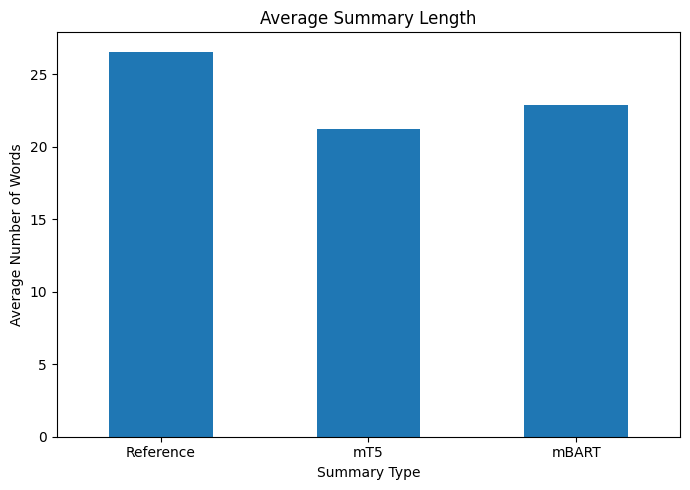

In [28]:
lengths = pd.DataFrame({
    "Reference": [len(normalize_hindi(x).split()) for x in references],
    "mT5": [len(normalize_hindi(x).split()) for x in mt5_predictions],
    "mBART": [len(normalize_hindi(x).split()) for x in mbart_predictions]
})

display(lengths.describe().round(2))

lengths.mean().plot(kind="bar", figsize=(7,5))
plt.title("Average Summary Length")
plt.xlabel("Summary Type")
plt.ylabel("Average Number of Words")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 28. Save All Results


In [29]:
results.to_csv(
    "Experiment_8_Final_Model_Comparison.csv",
    index=False
)

winners.to_csv(
    "Experiment_8_Metric_Winners.csv",
    index=False
)

detailed.to_csv(
    "Experiment_8_Detailed_Predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Saved:")
print("1. Experiment_8_Final_Model_Comparison.csv")
print("2. Experiment_8_Metric_Winners.csv")
print("3. Experiment_8_Detailed_Predictions.csv")


Saved:
1. Experiment_8_Final_Model_Comparison.csv
2. Experiment_8_Metric_Winners.csv
3. Experiment_8_Detailed_Predictions.csv


# Result

Hindi abstractive text summarization was implemented using **mT5** and **mBART** XL-Sum summarization checkpoints. Both models were evaluated on the same randomly selected Hindi XL-Sum test articles.

Unlike the earlier run, ROUGE is calculated using **Hindi-aware Unicode normalization and whitespace tokenization**, preventing Devanagari text from being incorrectly reduced to near-zero overlap.

The experiment reports:
- ROUGE-1 F1
- ROUGE-2 F1
- ROUGE-L F1
- multilingual BERTScore Precision
- multilingual BERTScore Recall
- multilingual BERTScore F1
- per-example results
- metric variability
- automatic metric-wise winners

# Conclusion

ROUGE and multilingual BERTScore measure complementary aspects of summarization quality. Hindi-aware ROUGE measures lexical overlap, while multilingual BERTScore measures contextual semantic similarity.

The final conclusion should use the automatically generated comparison table and metric-winner table from the actual Colab run. This avoids claiming that one model is better before observing the experimental results.
